# Лекция 6. Глобализация: линейный поиск, доверительная область и сопряжённые градиенты

**Курс:** Вычислительная оптимизация · **Часть II. Безусловная оптимизация и ньютоновские методы** · Лекция 6 из 16 · 14 октября 2026

**Материалы:** [конспект-ноутбук с кодом демонстраций](lecture06.ipynb) · [демо-ноутбук](demo06.ipynb) · [семинар: глобализация в CasADi и IPOPT](seminar06.ipynb) · [разбор упражнений](exercises06.ipynb) · [интерактивная страница «Армихо, Вольфе, доверительная область, CG»](https://claude.ai/artifact/KniuVJGw3XPZvWVeDtBpwE)

В конспекте-ноутбуке три демонстрации стоят прямо в тексте: «Демо (a)» — линейный поиск — после раздела 2, «Демо (b)» — доверительная область — после раздела 3, «Демо (c)» — сопряжённые градиенты — после раздела 4. Задачи-крючки и биография цепи — только в `demo06.ipynb` (части (0) и (d)).

---

> **Код в этом ноутбуке.** Три демонстрации из [`demo06.ipynb`](demo06.ipynb) вставлены в те разделы, к которым относятся: «Демо (a)» — линейный поиск — после раздела 2, «Демо (b)» — доверительная область — после раздела 3, «Демо (c)» — сопряжённые градиенты — после раздела 4; крючки и биография цепи — только в `demo06.ipynb`. Вспомогательный код (палитра, методы `armijo`, `wolfe`, `newton_ls`, `bfgs`, `trust_region`, `cg`, `newton_cg`, задачи) вынесен в [`l6helpers.py`](l6helpers.py); его подключает ячейка ниже.

In [1]:
%matplotlib inline

from l6helpers import *  # палитра, методы, задачи (см. файл рядом)

## Пять шагов — и двадцать три миллиарда

Возьмите функцию $f(x)=x\arctan x-\tfrac12\ln(1+x^2)$: гладкую, **строго выпуклую**, с единственным минимумом в нуле. Запустите из $x_0=2$ метод Ньютона:

$$
2\ \to\ -3.54\ \to\ 13.95\ \to\ -279\ \to\ 1.2\cdot10^{5}\ \to\ -2.3\cdot10^{10}.
$$

Пять шагов — и точка улетела на 23 миллиарда. Тот же Ньютон, которому разрешили укорачивать шаг по правилу Армихо, приходит в минимум за **5 итераций**.

**Почему так.** $f'(x)=\arctan x$, $f''(x)=\dfrac{1}{1+x^2}>0$. Шаг Ньютона — вершина параболы-модели $m_k(p)=f(x_k)+f'(x_k)\,p+\tfrac12f''(x_k)\,p^2$:

$$
x_{k+1}=x_k-\frac{f'(x_k)}{f''(x_k)}=x_k-(1+x_k^2)\arctan x_k .
$$

<img src="img/00_atan_newton.png" width="900" alt="слева: f = x arctan x − ½ ln(1+x²) и парабола-модель в x₀ = 2 — её вершина x₁ = −3.54 обещает f = −1.65, а на самом деле там f = 3.28, половина шага даёт 0.27; справа: f' = arctan x с полками ±π/2 — касательная в 2 пересекает ось в −3.54, касательная в −3.54 — в 13.95; порог старта ±1.39">

*Слева: парабола-модель в $x_0=2$ обещает в вершине $x_1=-3.54$ значение $-1.65$, а на самом деле там $f=3.28$ — хуже, чем было ($1.41$); половина шага (синий квадрат) даёт $0.27$. Справа: тот же метод как Ньютон для уравнения $f'(x)=\arctan x=0$ — касательная к почти горизонтальной кривой пересекает ось всё дальше.*

| $k$ | чистый Ньютон, $x_k$ | с Армихо, $x_k$ | $\alpha_k$ |
|---|---|---|---|
| 0 | $2$ | $2$ | — |
| 1 | $-3.54$ | $-0.77$ | $\tfrac12$ |
| 2 | $13.95$ | $0.27$ | $1$ |
| 3 | $-279$ | $-0.013$ | $1$ |
| 4 | $1.2\cdot10^{5}$ | $1.6\cdot10^{-6}$ | $1$ |
| 5 | $-2.3\cdot10^{10}$ | $3\cdot10^{-18}$ | $1$ |

- **Направление всегда верное:** $f''>0$, и шаг $-(1+x^2)\arctan x$ имеет знак, противоположный $x$, — всегда к нулю.
- **Длину парабола врёт:** $f''\to0$ вдали от нуля, парабола с крошечной кривизной очень широка, и её вершина лежит далеко за минимумом; касательная к полке $\pm\pi/2$ пересекает ось далеко.
- **Ошибка возводится в квадрат — и растёт:** при $\lvert x_k\rvert\gg1$ шаг $\approx\tfrac{\pi}{2}x_k^2$, то есть $\lvert x_{k+1}\rvert\approx\tfrac{\pi}{2}x_k^2$ — та же формула, что у квадратичной сходимости $\lvert e_{k+1}\rvert\le C\lvert e_k\rvert^2$, только $C\lvert e_k\rvert>1$. Чистый Ньютон сходится лишь из $\lvert x_0\rvert<1.39$: с порога шаг переносит ровно в $-x_0$.

Армихо отверг полный шаг ($3.28>1.41$) и принял половину ($0.27$); дальше точка внутри порога, и шаги полные. **Модель назначает направление, длину шага проверяет функция** — в этом вся лекция.

### Ещё два крючка

<img src="img/00_hooks.png" width="900" alt="три задачи-крючка: Ньютон на арктангенсе улетает за пять шагов, а с Армихо сходится; Химмельблау — треть стартов чистого Ньютона кончается в седле или максимуме; цепь из 400 грузов — спуск 937 503 итерации против 200 у сопряжённых градиентов">

- **Химмельблау:** из $36\,\%$ стартов чистый Ньютон приходит не в минимум, а в седло или в максимум. Метод доверительной области из тех же стартов — **в минимум из $100\,\%$**.
- **Цепь из $400$ грузов** ($800$ переменных): градиентный спуск — $937\,503$ итерации, метод сопряжённых градиентов — **$200$**. Итерация у обоих стоит одинаково: одно умножение матрицы на вектор.

### Проблема и три ответа

Ньютон, BFGS и Гаусс–Ньютон — методы *локальные*: быстрые рядом с решением и слепые вдали от него, потому что квадратичная модель честна лишь в окрестности точки. Сегодняшняя тема — **глобализация** (*globalization*): как заставить метод сходиться из любого старта, не потеряв скорость вблизи решения.

**Зачем это вам.** Каждый солвер устроен как «локальный двигатель + глобализация»: SciPy, IPOPT, MATLAB, Ceres, PyTorch. Пока всё работает, глобализации не видно; когда ломается, в логе появляются `alpha_pr = 0.125`, `lg(rg) = 2.0`, «Desired error not necessarily achieved due to precision loss» — и без сегодняшней лекции эти строки ничего не говорят.

**Главный герой лекции — доверие к модели.** Насколько верить $m_k(p)$ и как решать это автоматически — три ответа:

1. **Линейный поиск** (*line search*): направление — из модели, длина шага — по самой функции (раздел 2).
2. **Доверительная область** (*trust region*): сначала радиус, в котором модели верим, потом шаг; радиус настраивается сам (раздел 3).
3. **Сопряжённые градиенты** (*conjugate gradients*, CG): почти ньютоновская скорость, когда матрицу $n\times n$ не построить и не обратить (раздел 4).

## 1. Повторение: что мы уже умеем

Лекция начинается с десяти минут повторения: сегодняшние методы — надстройка над всем, что было в лекциях 1–5.

### 1.1. Пять лекций на одной странице

| Лекция | Главная мысль | Число, которое стоит помнить | Где |
|---|---|---|---|
| 1 | Задача = переменные + цель + ограничения; классы LP, QP, выпуклые, NLP; численно решить = найти точку с заданной точностью | цепь: первая сквозная задача | Л1, §3, §6, §7.3 |
| 2 | Выпуклая задача: локальный минимум = глобальный; проверка — гессиан $\succeq0$ | — | Л2, §4, §6 |
| 3 | С ограничениями в решении антиградиент уравновешен нормалями активных ограничений; множители — силы и цены (ККТ) | цепь на полу: множители = силы реакции | Л3, §4–8 |
| 4 | Без ограничений: $\nabla f=0$, $\nabla^2f\succeq0$; спуск сходится линейно, итераций $\sim\kappa$ | Розенброк: $13\,756$ итераций, $\kappa=2508$; цепь $N=40$: $10\,575$ | Л4, §2–5 |
| 5 | Один рецепт «линеаризуй и реши» — Ньютон, BFGS, Гаусс–Ньютон; квадратичная и сверхлинейная сходимость вблизи решения; Армихо и сдвиг $\tau I$ вдали | Розенброк: Ньютон $7$, с Армихо $22$, BFGS $34$; цепь: Ньютон $1$, BFGS с точным шагом $20$ | Л5, §2–6 |

### 1.2. Одна формула и что в ней уже заполнено

Все методы части II — это

$$
\boxed{\;x_{k+1}=x_k+\alpha_kp_k,\qquad p_k=-B_k^{-1}\nabla f(x_k)\;}
$$

**Направление** $p_k$ задаёт матрица кривизны $B_k$: что метод знает о функции. **Длину** задаёт $\alpha_k$. Лекция 4 научилась выбирать $\alpha_k$ для спуска ($B_k=I$), лекция 5 — выбирать $B_k$: гессиан, BFGS, $J^\top J$, $J^\top J+\lambda I$.

<img src="img/01_review.png" width="900" alt="повторение: пути спуска, чистого и демпфированного Ньютона и BFGS на Розенброке и число итераций каждого; справа биография цепи — 10 575, 20, 1 и пустая строка для сегодняшнего метода">

| Метод | $B_k$ | $\alpha_k$ | Скорость вблизи решения | Розенброк из $(-1.2,1)$ |
|---|---|---|---|---|
| градиентный спуск (Л4) | $I$ | backtracking | линейная, множитель $\approx1-1/\kappa$ | $13\,756$ |
| Ньютон (Л5) | $\nabla^2f(x_k)$ | $1$ | квадратичная | $7$ (с выбросом до $(0.76,-3.18)$) |
| Ньютон + Армихо (Л5) | $\nabla^2f$ или $\nabla^2f+\tau I$ | Армихо | квадратичная | $22$ |
| BFGS (Л5) | из секущего уравнения | Армихо | сверхлинейная | $34$ |
| Левенберг–Марквардт (Л5) | $J^\top J+\lambda_kI$ | $1$, а $\lambda_k$ — по $\rho$ | почти квадратичная | синус: $7$ вычислений $r$ |

Две колонки остались открытыми: **почему** правило Армихо гарантирует сходимость (и гарантирует ли) и **что делать**, когда $B_k$ нельзя ни построить, ни обратить. Это и есть сегодняшняя лекция.

### 1.3. Блиц: шесть вопросов

Ответ — одной фразой; если не получается, ссылка ведёт туда, где он есть.

1. Чем выпуклая задача приятнее невыпуклой?
2. Что в точке минимума с ограничениями уравновешивает антиградиент?
3. Почему спуск на Розенброке делает $13\,756$ итераций?
4. Когда шаг Ньютона ведёт *вверх* по функции?
5. Что измеряет секущее уравнение $B_{k+1}s_k=y_k$?
6. Что Гаусс–Ньютон отбрасывает от гессиана и зачем Левенберг–Марквардт добавляет $\lambda I$?

<details>
<summary>Ответы</summary>

1. Любой локальный минимум глобален, а условие $\nabla f=0$ — не только необходимое, но и достаточное (Л2, §6–7).
2. Нормали активных ограничений с неотрицательными множителями — «силы реакции» (Л3, §4–5).
3. Число обусловленности гессиана у решения $\kappa=2508$: зигзаг поперёк узкой долины, итераций $\sim\kappa\ln(1/\varepsilon)$ (Л4, §5).
4. Когда гессиан индефинитен: модель — седло, и решение $\nabla^2f\,p=-g$ — её седловая точка (Л5, §3.4).
5. Кривизну вдоль сделанного шага — по разности градиентов, без вторых производных (Л5, §4.2).
6. Отбрасывает $\sum_ir_i\nabla^2r_i$ — дорогую половину гессиана; $\lambda I$ укорачивает шаг там, где линейная модель невязок врёт (Л5, §5.2–5.3).

</details>

### 1.4. Что сегодня

Линейный поиск: правило Армихо, условия Вольфе, теорема о глобальной сходимости и куда она ведёт — в минимум или в седло (раздел 2) → доверительная область: отношение $\rho$, точка Коши, dogleg, Левенберг–Марквардт как частный случай (3) → сопряжённые градиенты: Ньютон без матрицы, CG внутри Ньютона (4) → что из этого видно в SciPy и в логе IPOPT (5). Семинар — за ноутбуком: глобализация в CasADi и IPOPT (раздел 8).

## 2. Линейный поиск: длину шага проверяет функция

**Тезис простыми словами.** Модель хорошо знает, *куда* идти, но плохо — *на сколько*. Поэтому направление $p_k$ берём из модели, а длину $\alpha$ подбираем, глядя на настоящую функцию вдоль этого направления.

**Аналогия.** Строитель принёс смету: «уроним $f$ на 10 единиц». Вы принимаете работу, только если реально сделано *хотя бы небольшую долю* обещанного. Не сделано — смету урезают вдвое и проверяют снова. Это правило Армихо. Условие Вольфе добавляет второй пункт: не принимать работу, сделанную «на полшага», когда до цели ещё далеко.

### 2.1. Функция одной переменной $\varphi(\alpha)$

Зафиксируем точку $x_k$ и направление спуска $p_k$ ($g_k^\top p_k<0$). Всё, что происходит вдоль луча, — функция одной переменной:

$$
\varphi(\alpha)=f(x_k+\alpha p_k),\qquad \varphi(0)=f(x_k),\qquad \varphi'(0)=g_k^\top p_k<0 .
$$

$\varphi'(0)$ — это обещание линейной модели: на единицу длины шага функция должна падать на $\lvert g_k^\top p_k\rvert$.

**Пример — тот самый выброс с картинки повторения.** Розенброк, точка $x_1=(-1.175,\,1.381)$ — первая итерация Ньютона из $(-1.2,1)$. Шаг Ньютона $p_1=(1.94,\,-4.56)$ длиной $4.95$ ведёт в $(0.76,\,-3.18)$, где $f=1412$ — в $300$ раз больше, чем $\varphi(0)=4.73$. А при $\alpha\approx0.11$ функция падает до $4.06$. Модель угадала направление и катастрофически ошиблась с длиной.

### 2.2. Правило Армихо: зачем нужна добавка $c_1$

**Правило Армихо** (*Armijo*, 1966):

$$
\varphi(\alpha)\le\varphi(0)+c_1\,\alpha\,\varphi'(0),\qquad 0<c_1<1,\quad\text{обычно } c_1=10^{-4}.
$$

Справа — прямая, проведённая из $\varphi(0)$ с наклоном в $c_1$ раз положе касательной. Принимаем шаг, если график $\varphi$ лежит под этой прямой.

Зачем $c_1$, если можно просто требовать «стало меньше»? Возьмём $f(x)=x^2$ и направление спуска $p_k=-f'(x_k)=-2x_k$. Длину шага выберем *нарочно плохо*: $\alpha=\tfrac12$ привела бы в минимум за один шаг (это шаг Ньютона), $\alpha=1$ — в зеркальную точку $-x_k$, где $f$ та же. Берём $\alpha_k$ чуть меньше единицы, так что $x_{k+1}=-x_k\cdot\dfrac{1+2^{-k-1}}{1+2^{-k}}$: из $x_0=2$ получаем $-1.5,\ 1.25,\ -1.125,\dots$, то есть $x_k=(-1)^k(1+2^{-k})$. Каждый шаг уменьшает $f$, и правило «стало меньше» принимает их все, но точки прыгают через нуль и сходятся к $\pm1$, где $f'=\pm2\ne0$. Уменьшение $f_k-f_{k+1}\approx2^{-k}$ всё мельче обещания касательной $\alpha_k\lvert\varphi'(0)\rvert\approx4$. Правило Армихо требует долю $c_1$ от обещания, фиксированные $\approx4c_1$, и при $c_1=10^{-4}$ отвергает такие шаги с $k=12$; backtracking делит $\alpha$ пополам, и точка оказывается у нуля. Дело не в методе, Ньютон решил бы $x^2$ за шаг, а в правиле приёмки: любое правило, пропускающее эти шаги, не даст теоремы §2.5 (упражнение 6.1).

<img src="img/02_armijo_c1.png" width="900" alt="слева: φ(α) вдоль шага Ньютона из x₀ = 2 на арктангенсе, касательная в нуле и прямые Армихо при c₁ = 0.25 и 10⁻⁴; α = 1 (φ = 3.28) выше прямой — отказ, α = ½ (0.27) под ней — принят; справа: парабола x², точки x_k = (−1)^k(1+2^−k) прыгают через нуль, f убывает к 1, f' → ±2, с k = 12 правило Армихо нарушено">

*Слева: $\varphi(\alpha)$ вдоль шага Ньютона из $x_0=2$ на арктангенсе из крючка — $\alpha=1$ выше прямой Армихо, $\alpha=\tfrac12$ под ней; при обычном $c_1=10^{-4}$ прямая почти горизонтальна. Справа: на $x^2$ точки прыгают через нуль, $f$ убывает к $1$, но каждое уменьшение $\approx2^{-k}$ всё меньше требования $c_1\alpha_k\lvert\varphi'(0)\rvert\approx4c_1$ — с $k=12$ правило Армихо нарушено.*

### 2.3. Backtracking: шаг не слишком длинный и не слишком короткий

Процедура: $\alpha=1$; пока Армихо не выполнено, $\alpha\leftarrow\alpha/2$.

- **Цикл конечен.** При малых $\alpha$ функция идёт почти по касательной, а требуем мы лишь долю $c_1<1$ от её наклона.
- **Шаг не слишком короткий.** По лемме о спуске $\varphi(\alpha)\le\varphi(0)+\alpha\varphi'(0)+\tfrac L2\alpha^2\lVert p\rVert^2$, где $L$ — константа Липшица градиента. Значит, Армихо выполнено для всех $\alpha\le\bar\alpha=2(1-c_1)\lvert\varphi'(0)\rvert/(L\lVert p\rVert^2)$, и деление пополам остановится на $\alpha\ge\min(1,\bar\alpha/2)$. Это неравенство — ключ к теореме §2.5.

На Розенброке из $x_1$ backtracking пробует $\alpha=1$ ($f=1412$), $\tfrac12$, $\tfrac14$ — отказ, $\tfrac18$ — принято: Армихо выполнено при всех $\alpha\le0.176$. Это вторая итерация демпфированного Ньютона. **Тот же шаг $0.125$ на той же итерации делает IPOPT** (столбец `alpha_pr` его лога, семинар). На арктангенсе из введения backtracking пробует $\alpha=1$ ($f=3.28$) — отказ, $\tfrac12$ ($f=0.27$) — принято; дальше все $\alpha=1$.

<img src="img/11_backtracking.gif" width="900" alt="анимация: backtracking на графике φ(α) для Розенброка в точке x_1 — кандидаты α = 1, 1/2, 1/4 выше прямой Армихо и отвергнуты, 1/8 принят; справа те же точки на линиях уровня">

*Анимация: слева $\varphi(\alpha)$ и прямая Армихо, кандидаты $1,\tfrac12,\tfrac14$ отвергнуты, $\tfrac18$ принят; справа те же точки на линиях уровня Розенброка — длинный шаг Ньютона урезан до восьмой части.*

### 2.4. Условия Вольфе: шаг должен быть достаточно длинным

Армихо отсекает слишком длинные шаги. Сверху длина не ограничена, а снизу её держит только backtracking, стартующий с $\alpha=1$. Метод, который выбирает шаг иначе (экстраполирует, интерполирует), может принять бесполезно короткий шаг. **Условие кривизны Вольфе** (*Wolfe*, 1969) это запрещает:

$$
\varphi'(\alpha)\ge c_2\,\varphi'(0),\qquad c_1<c_2<1 .
$$

Наклон в новой точке должен стать *заметно положе*: на крутом склоне, где ещё есть куда спускаться, останавливаться нельзя. **Сильные условия Вольфе** требуют ещё и не перескакивать далеко за минимум $\varphi$: $\lvert\varphi'(\alpha)\rvert\le c_2\lvert\varphi'(0)\rvert$. Стандартные значения: $c_1=10^{-4}$; $c_2=0.9$ для Ньютона и квази-Ньютона, $c_2=0.1$–$0.4$ для нелинейного CG.

**Вопрос залу.** На графике $\varphi(\alpha)$ для Розенброка в $x_1$ три кандидата: $\alpha=0.02$, $\alpha=0.125$, $\alpha=0.25$. Какие проходят Армихо? Какие — Вольфе?

<img src="img/02_armijo_wolfe.png" width="900" alt="φ(α) для Розенброка в x_1 вдоль шага Ньютона: прямая Армихо, допустимые по Армихо шаги α ≤ 0.176, по Вольфе 0.044 ≤ α ≤ 0.176; кандидаты 0.02 — только Армихо, 0.125 — оба условия, 0.25 — ни одного">

Покрутить руками — сцена «Армихо и Вольфе» на [интерактивной странице](https://claude.ai/artifact/KniuVJGw3XPZvWVeDtBpwE): ползунки $c_1$, $c_2$ и $\alpha$, кнопка backtracking.

*Ответ на картинке:*
- $\alpha=0.02$ проходит Армихо, но не Вольфе: склон ещё крутой;
- $\alpha=0.125$ проходит оба условия;
- $\alpha=0.25$ не проходит Армихо: перелёт.

Допустимые шаги: по Армихо $\alpha\le0.176$, по Вольфе $0.044\le\alpha\le0.176$.

**Зачем Вольфе квази-Ньютону.** BFGS сохраняет $H_k\succ0$, только если $s_k^\top y_k>0$. Условие кривизны гарантирует это в одну строку:

$$
s_k^\top y_k=\alpha\,\big(\nabla f(x_{k+1})-\nabla f(x_k)\big)^\top p_k\ge\alpha\,(c_2-1)\,g_k^\top p_k>0 .
$$

Проверка на Химмельблау, $400$ случайных стартов: с одним Армихо в $72$ запусках ($18\,\%$) встречаются шаги с $s^\top y\le0$ — всего $179$ таких шагов, и обновление BFGS приходится пропускать. С Вольфе — **ни одного**: так обещает формула выше.

**Честный разбор цепи (упражнение 11.9).** На прошлой лекции BFGS с одним Армихо не сошёлся на цепи $N=40$ за $10\,000$ итераций, и виноватым назначили отсутствие условия Вольфе. Проверим.

| Гипотеза | Проверка | Вывод |
|---|---|---|
| виновато отсутствие Вольфе | энергия цепи — выпуклая квадратичная, $s^\top y=s^\top Hs>0$ при любом шаге; с сильным Вольфе тот же BFGS застревает так же | нет |
| виноват масштаб $H_0=I$ | первое направление $-g$ в сотни раз длиннее разумного шага; пары $(s,y)$ получаются крошечными, обновление пропускается — матрица не учится | да |
| лекарство: $H_0\leftarrow\dfrac{s^\top y}{y^\top y}I$ после первого шага | $27$ итераций при $N=40$ ($17$ при $N=20$, $47$ при $N=80$), с Армихо и с Вольфе одинаково; L-BFGS делает это на каждой итерации | работает |
| предел — округление | при $\lVert g\rVert\approx\sqrt{2\lambda_{\max}\varepsilon\lvert E\rvert}\approx1.3\cdot10^{-6}$ разность $E$ тонет в округлении — поиск не отличает «лучше» от «хуже», SciPy пишет «precision loss» (упражнение 6.10) | точный шаг и CG не сравнивают $f$ и доходят |

<img src="img/03_bfgs_wolfe.png" width="900" alt="слева: Химмельблау, 400 стартов BFGS — у одного Армихо 72 запуска с шагами, где s^T y ≤ 0, у Вольфе ни одного; справа: цепь N=40 — BFGS с H_0 = I застревает и с Армихо, и с Вольфе, с масштабированной H_0 сходится за 27 итераций, точный шаг — за 20; серая полоса — пол округления">

**Реальный кейс.** SciPy `minimize(method="BFGS")` использует сильные условия Вольфе ($c_1=10^{-4}$, $c_2=0.9$), `"CG"` — $c_2=0.4$. В PyTorch `torch.optim.LBFGS` по умолчанию идёт **без** линейного поиска, с постоянным `lr`; сильный Вольфе включает аргумент `line_search_fn="strong_wolfe"`.

### 2.5. Теорема о глобальной сходимости

**Теорема** (глобальная сходимость линейного поиска с backtracking по Армихо; Диль, *Globalization Strategies*; Nocedal & Wright, теорема 3.2 Зойтендейка). Пусть:
- $f$ ограничена снизу;
- $\nabla f$ липшицев с константой $L$;
- направления $p_k=-B_k^{-1}g_k$, где собственные числа симметричных $B_k$ лежат в $[m_B,\,M_B]$, $m_B>0$;
- $\alpha_k$ выбирается backtracking по Армихо от $\alpha=1$.

Тогда $\lVert\nabla f(x_k)\rVert\to0$ **из любого старта**.

**Доказательство в четыре строки** (идея: «каждый шаг съедает кусок $\lVert g\rVert^2$, а съесть можно лишь конечное»):

1. Направление — спуск, и не вырожденное: $\lvert g^\top p\rvert=g^\top B^{-1}g\ge\lVert g\rVert^2/M_B$, $\lVert p\rVert\le\lVert g\rVert/m_B$.
2. Шаг не мельчает: по §2.3 $\alpha_k\ge\min\big(1,\,(1-c_1)\lvert g^\top p\rvert/(L\lVert p\rVert^2)\big)\ge\min\big(1,\,(1-c_1)m_B^2/(LM_B)\big)=:\alpha_{\min}>0$.
3. Убывание за шаг: $f_k-f_{k+1}\ge c_1\alpha_k\lvert g_k^\top p_k\rvert\ge\dfrac{c_1\alpha_{\min}}{M_B}\lVert g_k\rVert^2$.
4. Складываем по $k$: $\sum_k\lVert g_k\rVert^2\le\dfrac{M_B\,(f_0-\inf f)}{c_1\alpha_{\min}}<\infty$, значит $\lVert g_k\rVert\to0$. $\blacksquare$

**Что это значит для методов.**
- Градиентный спуск ($B=I$) — частный случай: сходится глобально.
- Арктангенс из крючка: Армихо держит итерации в множестве уровня $\{f\le f(2)\}=[-2,2]$, где $m_B=\tfrac15$, $M_B=L=1$, — Ньютон с Армихо сходится из любого старта, чистый ($\alpha_k\equiv1$) — только из $\lvert x_0\rvert<1.39$.
- Для Ньютона $m_B>0$ — **требование** держать $B_k\succ0$: сдвиг $B_k=\nabla^2f+\tau I$ — не косметика, а условие теоремы.
- Для BFGS глобальная сходимость на выпуклых задачах доказана с условиями Вольфе (Пауэлл, 1976; Nocedal & Wright, теорема 6.5).

**«Глобальная сходимость» ≠ «глобальный минимум».** Теорема гарантирует $\nabla f\to0$, то есть *стационарную точку*. Какую именно — зависит от того, как метод обходится с отрицательной кривизной. Химмельблау, сетка $300\times300$ стартов на $[-6,6]^2$:

| Метод | Минимумы | Сёдла | Максимум |
|---|---|---|---|
| чистый Ньютон | $64\,\%$ | $31\,\%$ | $4\,\%$ |
| Ньютон + Армихо, сдвиг $\tau I$ только при $g^\top p\ge0$ (как в ДЗ 3) | $79\,\%$ | $20\,\%$ | $0\,\%$ |
| Ньютон + Армихо, сдвиг всегда при $\lambda_{\min}\le0$ («модифицированный Ньютон», как в IPOPT) | $100\,\%$ | $0\,\%$ | $0\,\%$ |
| доверительная область (раздел 3) | $100\,\%$ | $0\,\%$ | $0\,\%$ |

Максимум исчез с появлением линейного поиска: спуск не может прийти туда, откуда всё ведёт вниз. Сёдла остались: если сдвигать гессиан лишь тогда, когда направление перестаёт быть спуском, рядом с седлом Ньютон честно в него сходится.

<img src="img/04_saddle_trap.png" width="900" alt="Химмельблау из старта (0.58, 2.15): Ньютон с Армихо и сдвигом только при подъёме за 5 итераций приходит в седло (0.09, 2.88), норма градиента падает до нуля; доверительная область из того же старта за 7 итераций приходит в минимум (3, 2)">

Старт $(0.58,\,2.15)$: Ньютон с Армихо за $5$ итераций приходит в седло $(0.09,\,2.88)$, и $\lVert\nabla f\rVert\to0$ — теорема выполнена! Доверительная область из той же точки за $7$ итераций приходит в минимум $(3,2)$, IPOPT — тоже за $7$.

**Аналогия.** Вода всегда стекает вниз и где-нибудь остановится — в низине или на перевале, если стоит ровно на гребне. Но в океан она не обязана попасть: глобальная сходимость — про «остановится», а не про «в самую глубокую точку».

**Реальный кейс.** Симулятор SPICE решает уравнения Кирхгофа с экспонентами диодов методом Ньютона: ток растёт как $e^{V/V_T}$, $V_T\approx26$ мВ, и лишний вольт в шаге — множитель $e^{38}\approx3\cdot10^{16}$. Поэтому SPICE ограничивает шаг по напряжению на p-n-переходе (*voltage limiting*) — та же глобализация, только вместо Армихо физически разумный предел шага.

### Демо (a). Линейный поиск: Армихо, Вольфе, глобальная сходимость

**Что проверяем.** На Розенброке в точке $x_1$ (первая итерация Ньютона из $(-1.2,1)$) шаг Ньютона длиной $4.95$ ведёт в $f=1412$. Армихо выполнено при $\alpha\le0.176$, Вольфе ($c_2=0.9$) — при $0.044\le\alpha\le0.176$; backtracking пробует $1,\tfrac12,\tfrac14$ и принимает $\tfrac18$.

In [2]:
x1 = X0_ROSEN - np.linalg.solve(rosen_hess(X0_ROSEN), rosen_grad(X0_ROSEN))
p1 = -np.linalg.solve(rosen_hess(x1), rosen_grad(x1))
phi = lambda a: rosen(x1 + a * p1)
dphi = lambda a: rosen_grad(x1 + a * p1) @ p1
print(f"x1 = {x1.round(4)}, |p1| = {np.linalg.norm(p1):.3f}, φ(0) = {phi(0):.3f}, φ(1) = {phi(1):.1f}, φ'(0) = {dphi(0):.3f}")

al = np.linspace(0, 0.3, 30001)
arm = np.array([phi(a) <= phi(0) + 1e-4 * a * dphi(0) for a in al])
wol = arm & np.array([dphi(a) >= 0.9 * dphi(0) for a in al])
print(f"Армихо: α ≤ {al[arm].max():.3f};  Вольфе: {al[wol].min():.3f} ≤ α ≤ {al[wol].max():.3f}   (в конспекте: 0.176; 0.044–0.176)")

for a in [1, 0.5, 0.25, 0.125]:
    ok = phi(a) <= phi(0) + 1e-4 * a * dphi(0)
    print(f"  α = {a:<6g} φ = {phi(a):9.3f}  Армихо: {'да — принят' if ok else 'нет'}")

x1 = [-1.1753  1.3807], |p1| = 4.951, φ(0) = 4.732, φ(1) = 1411.8, φ'(0) = -8.433


Армихо: α ≤ 0.176;  Вольфе: 0.044 ≤ α ≤ 0.176   (в конспекте: 0.176; 0.044–0.176)
  α = 1      φ =  1411.845  Армихо: нет
  α = 0.5    φ =    89.749  Армихо: нет
  α = 0.25   φ =     8.395  Армихо: нет
  α = 0.125  φ =     4.087  Армихо: да — принят


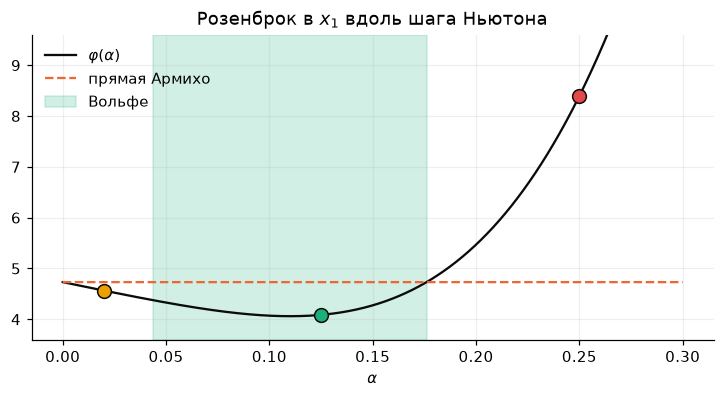

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(al, [phi(a) for a in al], color=INK, label=r"$\varphi(\alpha)$")
ax.plot(al, phi(0) + 1e-4 * al * dphi(0), "--", color=ORANGE, label="прямая Армихо")
ax.axvspan(al[wol].min(), al[wol].max(), color=AQUA, alpha=0.2, label="Вольфе")
for a, col in [(0.02, YELLOW), (0.125, AQUA), (0.25, RED)]:
    ax.plot(a, phi(a), "o", color=col, ms=9, mec=INK)
ax.set(ylim=(3.6, 9.6), xlabel=r"$\alpha$", title="Розенброк в $x_1$ вдоль шага Ньютона")
ax.legend(); plt.show()

**Сильный Вольфе своими руками.** Функция `wolfe` из второй ячейки (Nocedal & Wright, алгоритмы 3.5–3.6) на той же прямой: какой шаг она вернёт и сколько вычислений ей понадобится?

In [4]:
a, f_new, g_new, nf = wolfe(rosen, rosen_grad, x1, p1, rosen(x1), rosen_grad(x1))
print(f"сильный Вольфе: α = {a:.4f}, φ = {f_new:.4f}, |φ'(α)| / |φ'(0)| = {abs(g_new @ p1) / abs(dphi(0)):.3f} (≤ 0.9), вычислений {nf}")

сильный Вольфе: α = 0.1250, φ = 4.0874, |φ'(α)| / |φ'(0)| = 0.430 (≤ 0.9), вычислений 4


**Зачем Вольфе квази-Ньютону.** Условие кривизны гарантирует $s^\top y>0$. Проверяем на Химмельблау: BFGS из $400$ случайных стартов (`default_rng(2026)`), считаем шаги с $s^\top y\le0$. Ожидаем: с одним Армихо — $72$ запуска и $179$ таких шагов, с Вольфе — ни одного.

In [5]:
rng = np.random.default_rng(2026)
starts = rng.uniform(-6, 6, (400, 2))
for line in ["armijo", "wolfe"]:
    runs_bad = steps_bad = 0
    for x0 in starts:
        _, _, _, _, sy = bfgs(him, him_grad, x0, line=line, maxit=5000)
        neg = int(np.sum(sy[:, 0] <= 0)); runs_bad += neg > 0; steps_bad += neg
    print(f"{line:7s}: запусков с s^T y <= 0 — {runs_bad} из 400, таких шагов — {steps_bad}")

armijo : запусков с s^T y <= 0 — 72 из 400, таких шагов — 179


wolfe  : запусков с s^T y <= 0 — 0 из 400, таких шагов — 0


**Цепь: виноват масштаб $H_0$, а не Вольфе.** Энергия цепи — выпуклая квадратичная функция: $s^\top y=s^\top Hs>0$ при любом шаге, условие Вольфе ничего не добавляет. С $H_0=I$ BFGS застревает и с Армихо, и с Вольфе; с $H_0\leftarrow\frac{s^\top y}{y^\top y}I$ после первого шага — $27$ итераций.

In [6]:
E, gE, H, b, v0, unpack = make_chain(40)
for line, sc in [("armijo", False), ("wolfe", False), ("armijo", True), ("wolfe", True)]:
    x, k, _, nf, _ = bfgs(E, gE, v0, line=line, scale_H0=sc, maxit=3000)
    print(f"{line:7s} H0 {'масштабирована' if sc else '= I          '}: {k:5d} итераций, {nf:6d} вычислений E, |∇E| = {np.linalg.norm(gE(x)):.1e}")
lam_max = np.linalg.eigvalsh(H)[-1]
E_star = E(np.linalg.solve(H, -b))
print(f"пол округления sqrt(2 λmax ε |E*|) = {np.sqrt(2 * lam_max * np.finfo(float).eps * abs(E_star)):.2e}   (в конспекте ≈ 1.3e-6)")

armijo  H0 = I          :  3000 итераций, 102971 вычислений E, |∇E| = 1.5e-06


wolfe   H0 = I          :  3000 итераций, 123602 вычислений E, |∇E| = 7.9e-06
armijo  H0 масштабирована:    27 итераций,     29 вычислений E, |∇E| = 3.4e-07
wolfe   H0 масштабирована:    27 итераций,     29 вычислений E, |∇E| = 3.4e-07
пол округления sqrt(2 λmax ε |E*|) = 1.29e-06   (в конспекте ≈ 1.3e-6)


**Глобальная сходимость — к стационарной точке.** Ньютон с Армихо из ловушки $(0.58,\,2.15)$ на Химмельблау: со сдвигом $\tau I$ только при подъёме (как в Л5 и ДЗ 3) — в седло за $5$ итераций, с «модифицированным Ньютоном» (сдвиг всякий раз, когда $\lambda_{\min}\le10^{-3}$) — в минимум.

In [7]:
for shift in ["ascent", "always"]:
    x, k, _ = newton_ls(him, him_grad, him_hess, (0.58, 2.15), shift=shift)
    lam = np.linalg.eigvalsh(him_hess(x))
    print(f"сдвиг «{shift}»: {k} итераций → ({x[0]:.4f}, {x[1]:.4f}), |∇f| = {np.linalg.norm(him_grad(x)):.1e}, собственные числа {lam.round(2)}")

сдвиг «ascent»: 5 итераций → (0.0867, 2.8843), |∇f| = 6.9e-11, собственные числа [-31.71  75.51]
сдвиг «always»: 6 итераций → (3.0000, 2.0000), |∇f| = 0.0e+00, собственные числа [25.72 82.28]


## 3. Доверительная область: сначала радиус, потом шаг

**Тезис простыми словами.** Линейный поиск выбирает направление, а потом длину. Доверительная область делает наоборот: сначала решает, **в каком радиусе $\Delta$ модели можно верить**, и ищет лучшую точку модели внутри этого шара. Радиус настраивается сам — по тому, насколько модель угадала.

**Аналогия.** Кредитный лимит. Банк (алгоритм) выдаёт модели лимит доверия $\Delta$. Модель обещала уменьшить $f$ на 10, а принесла 9 — лимит удваивают. Принесла 1 — урезают вчетверо. Принесла рост $f$ — сделку отменяют и снова урезают лимит.

### 3.1. Подзадача и отношение $\rho$

На каждой итерации:

$$
\min_p\ m_k(p)=f_k+g_k^\top p+\tfrac12p^\top B_kp\qquad\text{при}\qquad\lVert p\rVert\le\Delta_k,
$$

$$
\rho_k=\frac{f(x_k)-f(x_k+p_k)}{m_k(0)-m_k(p_k)}=\frac{\text{фактическое уменьшение}}{\text{обещанное моделью}} .
$$

| $\rho_k$ | Модель | Шаг | Радиус |
|---|---|---|---|
| $\rho_k<\tfrac14$ | врёт | принять, только если $\rho_k>\eta$ | $\Delta/4$ |
| $\tfrac14\le\rho_k\le\tfrac34$ | терпима | принять | не менять |
| $\rho_k>\tfrac34$, шаг на границе | хороша и упёрлась в лимит | принять | $\min(2\Delta,\Delta_{\max})$ |

У нас $\eta=0.1$, $\Delta_0=1$, $\Delta_{\max}=10$ (Nocedal & Wright, алгоритм 4.1). Знаменатель всегда положителен: $p=0$ допустим, поэтому лучшая точка модели не хуже нуля.

**Вопрос залу.** Модель обещала уменьшить $f$ на $10$.
- Фактически $f$ уменьшилась на $12$. Чему равно $\rho$ и что делать с $\Delta$?
- А если $f$ выросла на $3$?

*Ответ:*
- $\rho=1.2$: шаг принимаем; если он лежал на границе, радиус удваиваем. Функция оказалась даже лучше модели.
- $\rho=-0.3$: шаг отвергаем, $\Delta\leftarrow\Delta/4$, решаем подзадачу заново из той же точки.

### 3.2. Вы уже пользовались доверительной областью

Левенберг–Марквардт — это доверительная область для Гаусса–Ньютона: та же $\rho$, те же правила, только вместо $\Delta$ подкручивается $\lambda$. Связь точная.

**Теорема (Moré–Sorensen, 1983).** $p^\ast$ решает подзадачу доверительной области тогда и только тогда, когда для некоторого $\lambda\ge0$:

$$
(B+\lambda I)\,p^\ast=-g,\qquad \lambda\,\big(\Delta-\lVert p^\ast\rVert\big)=0,\qquad B+\lambda I\succeq0 .
$$

Читаем:
- $\lambda$ — множитель Лагранжа ограничения $\lVert p\rVert\le\Delta$;
- шаг внутри шара ($\lambda=0$) — обычный шаг Ньютона;
- шаг на границе — Ньютон со сдвигом $\lambda I$, ровно как у Левенберга–Марквардта и как $\tau I$ у демпфированного Ньютона;
- маленький $\Delta$ ↔ большой $\lambda$ ↔ короткий шаг почти против градиента.

Три лекарства — сдвиг $\tau I$, сдвиг $\lambda I$ и укороченный шаг — оказались одним и тем же объектом.

### 3.3. Как вычислить шаг: точка Коши, dogleg, точное решение

<img src="img/05_tr_subproblem.png" width="900" alt="подзадача доверительной области: слева модель-чаша g = (3, 4), B = diag(1, 2) — эллипсы, круги Δ = 1, 2, 3, точки Коши, ломаная dogleg, кривая точных решений и точка Ньютона (−3, −2); справа модель-седло у Химмельблау в (0.4, 2) — точный шаг уходит на границу вдоль отрицательной кривизны">

Слева на картинке — модельная задача $g=(3,4)$, $B=\operatorname{diag}(1,2)$: точка Ньютона $(-3,-2)$ лежит на расстоянии $3.61$, а при $\Delta=1$ точка Коши — $(-0.6,-0.8)$.

**Точка Коши** — минимум модели вдоль антиградиента внутри шара:

$$
p_C=-\tau\,\frac{\Delta}{\lVert g\rVert}\,g,\qquad
\tau=\begin{cases}1,& g^\top Bg\le0,\\ \min\!\Big(\dfrac{\lVert g\rVert^3}{\Delta\,g^\top Bg},\,1\Big),& g^\top Bg>0 .\end{cases}
$$

Это один шаг спуска с точной длиной, обрезанный шаром. Она гарантирует уменьшение модели $m(0)-m(p_C)\ge\tfrac12\lVert g\rVert\min(\Delta,\lVert g\rVert/\lVert B\rVert)$. А теорема о глобальной сходимости доверительной области требует от шага **лишь не меньше доли этого уменьшения** (Nocedal & Wright, теоремы 4.5–4.6). Любой шаг лучше точки Коши — законный.

**Только точка Коши — это спуск в маскировке:** на Розенброке $14\,110$ итераций. Сходится, но со скоростью спуска.

**Dogleg** (Powell, 1970) — ломаная из нуля в минимум модели вдоль $-g$, оттуда в точку Ньютона $p_B=-B^{-1}g$. Шаг — пересечение ломаной с границей шара (или сама $p_B$, если она внутри). Нужна $B\succ0$. На Розенброке — **24 итерации**, отвергнуто 3 шага.

**Точное решение** — $\lambda$ по теореме Moré–Sorensen ищется одномерным уравнением $\lVert(B+\lambda I)^{-1}g\rVert=\Delta$. При $n$ до нескольких тысяч это разложение $B$ на каждой итерации; на Розенброке — **25 итераций**.

**Отрицательная кривизна не страшна.** Если $B$ индефинитна, модель — седло. Безусловного минимума у неё нет, а в шаре минимум есть всегда (шар компактен). Точный шаг уходит на границу вдоль направления отрицательной кривизны — прочь от седла. Отсюда $100\,\%$ минимумов на Химмельблау без всякого сдвига $\tau I$.

<img src="img/07_basins_three.png" width="900" alt="Химмельблау, сетка 300 на 300: куда приходят чистый Ньютон (64% минимумы, 31% сёдла, 4% максимум), Ньютон с Армихо и сдвигом только при подъёме (79% минимумы, 21% сёдла) и доверительная область (100% минимумы)">

### 3.4. Доверительная область на Розенброке

<img src="img/06_tr_rosenbrock.png" width="900" alt="доверительная область с точным шагом на Розенброке из (-1.2, 1): путь и круги радиуса Δ_k; справа радиус Δ_k и отношение ρ_k по итерациям, три отвергнутых шага отмечены">

<img src="img/12_tr_breathes.gif" width="900" alt="анимация: доверительная область дышит — круг радиуса Δ_k вокруг текущей точки на Розенброке, точка модели и ρ_k в заголовке; радиус сжимается после неудачных шагов и растёт у решения">

*Анимация: круг доверия $\Delta_k$ вокруг текущей точки. После шагов с плохим $\rho$ он сжимается, на прямом участке долины — растёт. В заголовке кадра — номер итерации, $\Delta_k$ и $\rho_k$.*

Из $(-1.2,1)$:
- первый шаг Ньютона лежит внутри шара и принимается;
- во второй итерации шаг Ньютона длиной $4.95$ (тот самый выброс) обрезан до границы $\Delta=1$ — и всё равно $\rho=-0.43$: функция выросла, шаг отвергнут, $\Delta$ уменьшен вчетверо;
- дальше метод идёт по долине, радиус дышит;
- у решения шаги снова чисто ньютоновские.

Итого: $25$ итераций, из них $3$ пробных шага отвергнуты, ни одного подъёма по $f$. Покрутить руками — сцена «Доверительная область» на [интерактивной странице](https://claude.ai/artifact/KniuVJGw3XPZvWVeDtBpwE): клик задаёт старт, переключатель «точный / dogleg / точка Коши», снизу — подзадача в текущей точке.

**Линейный поиск или доверительная область?**

| | Линейный поиск | Доверительная область |
|---|---|---|
| сначала выбирается | направление | радиус |
| отрицательная кривизна | нужен сдвиг $\tau I$ | обрабатывается сама |
| неудачный шаг | укорачиваем вдоль того же луча | решаем подзадачу заново: шаг меняет и длину, и направление |
| цена итерации | одна система + несколько $f$ | подзадача (дороже), обычно одно $f$ |
| где | SciPy `BFGS`, `L-BFGS-B`, `Newton-CG`; IPOPT; PyTorch `LBFGS` | SciPy `trust-*`, `least_squares`; MATLAB `fsolve`; Ceres |

**Реальный кейс.** Google Ceres Solver решает задачи совмещения снимков и восстановления 3D-сцен из фотографий (*bundle adjustment*) с миллионами невязок. Внутри — доверительная область: Левенберг–Марквардт или dogleg на выбор. `scipy.optimize.least_squares` по умолчанию использует `method="trf"` — доверительную область, отражённую от границ. MATLAB `fsolve` по умолчанию — `"trust-region-dogleg"`.

### Демо (b). Доверительная область: $\rho$, точка Коши, dogleg

**Что проверяем.** Модельная задача $g=(3,4)$, $B=\operatorname{diag}(1,2)$: точка Ньютона $(-3,-2)$, модель в ней $-8.5$; при $\Delta=1$ точка Коши $(-0.6,-0.8)$, модель $-4.18$. Затем метод целиком на Розенброке: $25$ итераций, из них $3$ пробных шага отвергнуты.

In [8]:
g_t, B_t = np.array([3.0, 4.0]), np.diag([1.0, 2.0])
m = lambda p: g_t @ p + 0.5 * p @ B_t @ p
pN = -np.linalg.solve(B_t, g_t); pU = -(g_t @ g_t) / (g_t @ B_t @ g_t) * g_t
print(f"точка Ньютона {pN}, |pN| = {np.linalg.norm(pN):.3f}, m = {m(pN):.3f};  минимум вдоль -g: {pU.round(3)}, |pU| = {np.linalg.norm(pU):.3f}")
for D in [1.0, 2.0, 3.0, 4.0]:
    pc, pd, pe = cauchy_point(g_t, B_t, D), dogleg(g_t, B_t, D), tr_exact(g_t, B_t, D)
    print(f"Δ = {D}: Коши {pc.round(3)} m = {m(pc):7.3f} | dogleg {pd.round(3)} m = {m(pd):7.3f} | точный {pe.round(3)} m = {m(pe):7.3f}")

точка Ньютона [-3. -2.], |pN| = 3.606, m = -8.500;  минимум вдоль -g: [-1.829 -2.439], |pU| = 3.049
Δ = 1.0: Коши [-0.6 -0.8] m =  -4.180 | dogleg [-0.6 -0.8] m =  -4.180 | точный [-0.677 -0.736] m =  -4.204
Δ = 2.0: Коши [-1.2 -1.6] m =  -6.720 | dogleg [-1.2 -1.6] m =  -6.720 | точный [-1.494 -1.33 ] m =  -6.917
Δ = 3.0: Коши [-1.8 -2.4] m =  -7.620 | dogleg [-1.8 -2.4] m =  -7.620 | точный [-2.413 -1.783] m =  -8.280
Δ = 4.0: Коши [-1.829 -2.439] m =  -7.622 | dogleg [-3. -2.] m =  -8.500 | точный [-3. -2.] m =  -8.500


Точный шаг всегда не хуже dogleg, dogleg — не хуже точки Коши; при $\Delta\ge\lVert p_N\rVert=3.61$ все три — точка Ньютона. **Предскажите до запуска:** сколько итераций сделает доверительная область на Розенброке, если брать *только* точку Коши? (Подсказка: это спуск с точным шагом, обрезанным шаром.)

In [9]:
for step in ["exact", "dogleg", "cauchy"]:
    t0 = time.perf_counter()
    x, k, path, hist = trust_region(rosen, rosen_grad, rosen_hess, X0_ROSEN, step=step)
    rej = sum(not h[4] for h in hist)
    print(f"{step:7s}: {k:6d} итераций, отвергнуто {rej}, x = {x.round(6)}, {time.perf_counter() - t0:.1f} с")
print("в конспекте: 25 (3 отвергнуты), 24, 14 110; спуск с backtracking из Л4 — 13 756")

exact  :     25 итераций, отвергнуто 3, x = [1. 1.], 0.0 с
dogleg :     24 итераций, отвергнуто 3, x = [1. 1.], 0.0 с


cauchy :  14110 итераций, отвергнуто 2, x = [0.999999 0.999998], 0.2 с
в конспекте: 25 (3 отвергнуты), 24, 14 110; спуск с backtracking из Л4 — 13 756


**Таблица $\Delta_k$ и $\rho_k$** для точного шага: на итерации $1$ — тот самый выброс Л5 — шаг обрезан до $\Delta=1$, и всё равно $\rho<0$: шаг отвергнут, радиус вчетверо меньше.

In [10]:
x, k, path, hist = trust_region(rosen, rosen_grad, rosen_hess, X0_ROSEN, step="exact")
print(" k    Δ_k      ρ_k     шаг     |p|")
for i, (xk, p, D, rho, acc) in enumerate(hist):
    print(f"{i:2d}  {D:7.4f}  {rho:7.3f}   {'принят ' if acc else 'ОТВЕРГ.'}  {np.linalg.norm(p):.3f}")

 k    Δ_k      ρ_k     шаг     |p|
 0   1.0000    1.003   принят   0.381
 1   1.0000   -0.430   ОТВЕРГ.  1.000
 2   0.2500    1.014   принят   0.250
 3   0.5000    0.846   принят   0.500
 4   1.0000    1.281   принят   0.383
 5   1.0000    1.359   принят   0.244
 6   1.0000    1.096   принят   0.288
 7   1.0000    1.297   принят   0.117
 8   1.0000   -0.706   ОТВЕРГ.  0.316
 9   0.2500    0.479   принят   0.250
10   0.2500    1.137   принят   0.101
11   0.2500    0.062   ОТВЕРГ.  0.250
12   0.0625    1.006   принят   0.062
13   0.1250    0.956   принят   0.125
14   0.2500    1.031   принят   0.211
15   0.2500    1.244   принят   0.128
16   0.2500    0.524   принят   0.250
17   0.2500    1.110   принят   0.097
18   0.2500    0.222   принят   0.250
19   0.0625    1.033   принят   0.054
20   0.0625    0.985   принят   0.062
21   0.1250    1.088   принят   0.064
22   0.1250    1.041   принят   0.012
23   0.1250    1.004   принят   0.002
24   0.1250    1.000   принят   0.000


**Отрицательная кривизна.** Из ловушки $(0.58,2.15)$ доверительная область приходит в минимум $(3,2)$ — за $7$ итераций, без всякого сдвига: в шаре минимум модели есть всегда.

In [11]:
x, k, path, hist = trust_region(him, him_grad, him_hess, (0.58, 2.15), step="exact", tol=1e-10)
print(f"доверительная область: {k} итераций → {x.round(6)}; λ_min гессиана в старте = {np.linalg.eigvalsh(him_hess(np.array([0.58, 2.15])))[0]:.1f}")

доверительная область: 7 итераций → [3. 2.]; λ_min гессиана в старте = -31.3


## 4. Сопряжённые градиенты: Ньютон без матрицы

**Тезис простыми словами.** На квадратичной задаче спуск теряет время на зигзаг: каждый новый шаг портит то, что сделал предыдущий. Метод сопряжённых градиентов выбирает направления, которые **не портят друг друга**. Тогда каждое направление «закрывается» за один шаг навсегда, и на $n$ переменных хватает не больше $n$ шагов. За итерацию — одно умножение матрицы на вектор и $O(n)$ памяти.

**Аналогия.** Смеситель с двумя кранами — горячим и холодным. Покрутили горячий, чтобы стало теплее, — изменился и напор; поправили напор — сбилась температура. Это зигзаг спуска. Однорычажный смеситель: вверх-вниз — напор, влево-вправо — температура, ручки «не мешают» друг другу. Выставили одну, потом другую — готово за два движения. Сопряжённые направления — это такие ручки для квадратичной функции.

### 4.1. Сопряжённость и конечность

Квадратичная задача $f(x)=\tfrac12x^\top Ax-b^\top x$, $A\succ0$ — то же самое, что система $Ax=b$. Направления $d_0,d_1,\dots$ называются **$A$-сопряжёнными**, если $d_i^\top Ad_j=0$ при $i\ne j$. В координатах по сопряжённым направлениям $f$ распадается в сумму независимых одномерных парабол. Минимизируя по очереди вдоль $d_0,d_1,\dots$ (точный шаг), мы ни разу не портим сделанного: после $k$ шагов $x_k$ — минимум $f$ на всём подпространстве $x_0+\operatorname{span}\{d_0,\dots,d_{k-1}\}$.

**Следствие:** не больше $n$ итераций, а точнее — не больше числа **различных собственных чисел** $A$, «задетых» начальной ошибкой.

<img src="img/08_cg_ellipse.png" width="900" alt="эллипсы κ = 50 из старта (50, 1): спуск с точным шагом зигзагом за 567 итераций, сопряжённые градиенты — за 2; справа цепь N=40: норма градиента у спуска, CG, BFGS с точным шагом и нелинейного CG SciPy">

На эллипсе $\tfrac12(x_1^2+50x_2^2)$ из $(50,1)$: спуск с точным шагом — **567** итераций зигзагом, CG — **2**. Два собственных числа — два шага.

### 4.2. Алгоритм в пять строк

$r_0=Ax_0-b$ (это градиент), $d_0=-r_0$; затем для $k=0,1,\dots$

$$
\alpha_k=\frac{r_k^\top r_k}{d_k^\top Ad_k},\quad
x_{k+1}=x_k+\alpha_kd_k,\quad
r_{k+1}=r_k+\alpha_kAd_k,\quad
\beta_{k+1}=\frac{r_{k+1}^\top r_{k+1}}{r_k^\top r_k},\quad
d_{k+1}=-r_{k+1}+\beta_{k+1}d_k .
$$

- Новое направление — антиградиент плюс доля старого: **память об одном шаге**. Этого хватает для сопряжённости со *всеми* прошлыми направлениями.
- Матрица нужна только как операция $v\mapsto Av$: её можно не хранить.
- Скорость даже без конечности: $\lVert e_k\rVert_A\le2\Big(\dfrac{\sqrt\kappa-1}{\sqrt\kappa+1}\Big)^k\lVert e_0\rVert_A$ — итераций $\sim\sqrt\kappa$, а не $\sim\kappa$, как у спуска (как и было обещано).
- Авторы — Hestenes и Stiefel, 1952. Метод придуман для систем линейных уравнений и до сих пор — главный способ решать большие разреженные системы с $A\succ0$.

**Мини-задание.** Предскажите число итераций CG до $\lVert\nabla E\rVert\le10^{-6}$ на цепи $N=40$ (80 переменных). А при $N=400$ (800 переменных)?

<details>
<summary>Ответ</summary>

$20$ и $200$ — ровно $N/2$. У цепи горизонтальные координаты в старте (прямая между концами) уже точные, ошибка в них нулевая. Вертикальная ошибка симметрична относительно середины и задевает только $N/2$ симметричных собственных векторов. Столько различных «задетых» собственных чисел — столько и итераций (упражнение 6.9). Для сравнения: спуск — $10\,575$ и $937\,503$, $\kappa=681$ и $65\,170$. BFGS с точным шагом на квадратичной даёт **те же** $20$ итераций — на квадратичной функции с точным шагом он совпадает с CG.

</details>

<img src="img/09_cg_chain.png" width="900" alt="цепь: число итераций от числа грузов N в логарифмическом масштабе — спуск растёт как N², CG ровно N/2, Ньютон — одна итерация; справа сходимость CG при N = 40, 160, 400">

Покрутить руками — сцена «CG против спуска» на [интерактивной странице](https://claude.ai/artifact/KniuVJGw3XPZvWVeDtBpwE): ползунок $\kappa$ для эллипса и ползунок итерации $k$ для цепи (видно, как CG опускает провис от концов к середине).

**Биография цепи** (одна и та же задача, останов $\lVert\nabla E\rVert\le10^-6$):

| Лекция | Метод | $N=40$ | $N=400$ | Цена итерации |
|---|---|---|---|---|
| 4 | спуск, шаг $1/L$ | $10\,575$ | $937\,503$ | $Av$ |
| 5 | BFGS, точный шаг | $20$ | — | матрица $n\times n$ в памяти |
| 5 | Ньютон | $1$ | $1$ | решение системы $n\times n$ |
| **6** | **CG** | $\mathbf{20}$ | $\mathbf{200}$ | $Av$ — как у спуска |

### 4.3. CG внутри Ньютона: Newton-CG и Стейхауг

Для неквадратичной $f$ есть два способа использовать CG.

**Нелинейный CG** (Fletcher–Reeves, 1964; Polak–Ribière, 1969): та же формула, $r_k\to\nabla f(x_k)$, $\beta$ по градиентам, длина — линейным поиском по сильному Вольфе. На Розенброке SciPy `method="CG"` — $37$ итераций и $80$ вычислений $f$. На цепи — $266$ итераций вместо $20$: неточный поиск разрушает сопряжённость. Для квадратичной задачи всегда берите линейный CG.

**Newton-CG** (*truncated Newton*, неточный Ньютон):

1. систему Ньютона $\nabla^2f(x_k)\,p=-g_k$ решаем CG, а не точно;
2. CG останавливаем рано — при невязке $\le\eta_k\lVert g_k\rVert$, $\eta_k=\min(0.5,\sqrt{\lVert g_k\rVert})$, или при отрицательной кривизне $d^\top\nabla^2f\,d\le0$; вдали от решения хватает нескольких внутренних итераций, у решения $\eta_k\to0$ и шаг становится ньютоновским;
3. от гессиана нужны **только произведения $\nabla^2f\,v$** — их даёт алгоритмическое дифференцирование, не строя матрицу; в CasADi это одна строка `ca.jtimes(ca.gradient(f, x), x, v)`.

<img src="img/10_newton_cg.png" width="900" alt="Розенброк в 1000 переменных из точки 0.5: норма градиента у Newton-CG и L-BFGS-B по итерациям; справа число внутренних итераций CG на каждой внешней — растёт к концу, когда η_k → 0">

Розенброк в $1000$ переменных (`scipy.optimize.rosen`), старт $x_0=0.5\cdot\mathbf1$; матрица $1000\times1000$ — миллион чисел — **ни разу не построена**:

| Метод | Итераций | Произведений $\nabla^2f\,v$ |
|---|---|---|
| наш Newton-CG | $47$ | $225$ |
| SciPy `Newton-CG`, `hessp=rosen_hess_prod` | $54$ | $291$ |
| SciPy `L-BFGS-B` (`ftol=0`) | $88$ | — |

По умолчанию SciPy останавливает `L-BFGS-B` раньше — по относительному уменьшению $f$, на $78$-й итерации при $\lVert\nabla f\rVert\approx10^{-3}$.

**CG Стейхауга** (Steihaug, 1983) — тот же CG внутри доверительной области: стоп на отрицательной кривизне *или* при выходе на границу шара. Это SciPy `trust-ncg`: на Розенброке $29$ итераций, на цепи $N=40$ — $13$.

**Реальный кейс.** Библиотека LIBLINEAR, внутри scikit-learn, обучает логистическую регрессию на миллионах признаков методом TRON: доверительная область + CG Стейхауга, гессиан только в виде произведений на вектор (Lin, Weng, Keerthi, 2008). В scikit-learn есть и `LogisticRegression(solver="newton-cg")` — Newton-CG с линейным поиском.

### Демо (c). Сопряжённые градиенты

**Что проверяем.** На эллипсе $\tfrac12(x_1^2+50x_2^2)$ из $(50,1)$ CG сходится за $2$ шага (спуск с точным шагом — $567$, Л4); направления сопряжены: $d_1^\top Ad_0=0$. На цепи — ровно $N/2$ итераций.

In [12]:
A = np.diag([1.0, 50.0]); x = np.array([50.0, 1.0]); r = A @ x; d = -r; ds = []
for k in range(2):
    a = (r @ r) / (d @ A @ d); x = x + a * d; r_new = r + a * A @ d
    ds.append(d.copy()); d = -r_new + (r_new @ r_new) / (r @ r) * d; r = r_new
    print(f"итерация {k + 1}: x = {x.round(10)}")
print(f"сопряжённость d1^T A d0 = {ds[1] @ A @ ds[0]:.2e}")

итерация 1: x = [48.03921569 -0.96078431]
итерация 2: x = [0. 0.]
сопряжённость d1^T A d0 = -1.64e-11


**Предскажите до запуска:** сколько итераций CG на цепи из $400$ грузов ($800$ переменных)? А если стартовать не с прямой между концами, а со случайной точки?

In [13]:
for N in [10, 20, 40, 80, 160, 400]:
    _, gE_N, H_N, b_N, v0_N, _ = make_chain(N)
    _, k_sym, _ = cg(lambda v: H_N @ v, -b_N, v0_N)
    v_rand = v0_N + 0.1 * np.random.default_rng(2026).standard_normal(2 * N)
    _, k_rand, _ = cg(lambda v: H_N @ v, -b_N, v_rand)
    print(f"N = {N:3d}: CG из прямой — {k_sym:3d} (N/2 = {N // 2}), из случайного старта — {k_rand}")

N =  10: CG из прямой —   5 (N/2 = 5), из случайного старта — 10
N =  20: CG из прямой —  10 (N/2 = 10), из случайного старта — 20
N =  40: CG из прямой —  20 (N/2 = 20), из случайного старта — 40
N =  80: CG из прямой —  40 (N/2 = 40), из случайного старта — 80
N = 160: CG из прямой —  80 (N/2 = 80), из случайного старта — 160


N = 400: CG из прямой — 200 (N/2 = 200), из случайного старта — 400


Из прямой — ровно $N/2$: горизонтальная часть ошибки нулевая, вертикальная симметрична и задевает только $N/2$ собственных векторов (упражнение 6.9). Из случайного старта задеты все собственные векторы — итераций больше.

**Newton-CG в $1000$ переменных.** Розенброк из SciPy (`rosen`, `rosen_der`, `rosen_hess_prod`), старт $0.5\cdot\mathbf1$. Наш `newton_cg` берёт гессиан только как произведение на вектор. Ожидаем: $47$ итераций и $225$ произведений; SciPy `Newton-CG` — $54$ и $291$; `L-BFGS-B` — $88$ (с `ftol=0`).

In [14]:
x0 = np.full(1000, 0.5)
x, k, nmv, hist = newton_cg(rosen_nd, rosen_der, rosen_hess_prod, x0)
print(f"наш Newton-CG: {k} итераций, {nmv} произведений H v, f = {rosen_nd(x):.1e}")
r = minimize(rosen_nd, x0, jac=rosen_der, hessp=rosen_hess_prod, method="Newton-CG", options={"xtol": 1e-8})
print(f"SciPy Newton-CG: {r.nit} итераций, {r.nhev} произведений H v")
for ftol in [None, 0.0]:
    opts = {"gtol": 1e-6, "maxiter": 10_000} | ({} if ftol is None else {"ftol": ftol})
    r = minimize(rosen_nd, x0, jac=rosen_der, method="L-BFGS-B", options=opts)
    print(f"L-BFGS-B, ftol = {'по умолчанию' if ftol is None else 0}: {r.nit} итераций, |∇f| = {np.linalg.norm(rosen_der(r.x)):.1e}")

наш Newton-CG: 47 итераций, 225 произведений H v, f = 8.8e-21
SciPy Newton-CG: 54 итераций, 291 произведений H v
L-BFGS-B, ftol = по умолчанию: 78 итераций, |∇f| = 1.0e-03
L-BFGS-B, ftol = 0: 88 итераций, |∇f| = 1.4e-06


## 5. Что это даёт численно

- **Какой метод SciPy как глобализован.**

  | `minimize(method=…)` | Направление | Глобализация | Розенброк из $(-1.2,1)$ |
  |---|---|---|---|
  | `"BFGS"` | квази-Ньютон | сильный Вольфе, $c_2=0.9$ | $33$ итерации, $40$ вычислений $f$ |
  | `"L-BFGS-B"` | L-BFGS (память 10) | линейный поиск (Moré–Thuente) | $37$ (с `ftol=0`) |
  | `"CG"` | нелинейный CG (Polak–Ribière) | сильный Вольфе, $c_2=0.4$ | $37$ / $80$ |
  | `"Newton-CG"` | Ньютон, CG внутри | линейный поиск по Вольфе | $85$ |
  | `"trust-exact"` | Ньютон | доверительная область, точный шаг | $25$ |
  | `"dogleg"` | Ньютон | доверительная область, dogleg ($B\succ0$) | $24$ |
  | `"trust-ncg"` / `"trust-krylov"` | Ньютон, CG внутри | доверительная область, Стейхауг / Ланцош | $29$ / $38$ |

  Останов везде — $10^{-6}$, но по-разному: `BFGS` и `CG` — `gtol` в max-норме градиента, `trust-*` — в евклидовой, `Newton-CG` — по длине шага (`xtol=1e-8`), `L-BFGS-B` по умолчанию ещё и по относительному уменьшению $f$ (`ftol`) — без `ftol=0` он остановился бы на $36$-й итерации при $\lVert\nabla f\rVert=6\cdot10^{-5}$. Сравнивая солверы, всегда смотрите, *по какому критерию* они остановились.

  Есть гессиан и $n$ до тысяч — `trust-exact`. Гессиана нет — `BFGS`, при больших $n$ — `L-BFGS-B`. Есть произведения $\nabla^2f\,v$ при больших $n$ — `trust-ncg` или `Newton-CG`.
- **Лог IPOPT читается теперь построчно** (семинар):
  - `alpha_pr` — принятая длина шага: $1$ — полный ньютоновский шаг, $0.125$ — три деления пополам;
  - `ls` — число попыток линейного поиска;
  - `lg(rg)` — $\log_{10}$ сдвига гессиана, нашего $\tau$; прочерк — сдвига не было.

  На Розенброке IPOPT делает $21$ итерацию, а `alpha_pr` бывает $0.125$, $0.25$ и дважды $0.5$ — и первые двенадцать длин шага в точности совпадают с нашим Ньютоном с Армихо: $1,\ 0.125,\ 1,\ 1,\ 1,\ 0.25,\ 1,\ 1,\ 1,\ 0.5,\ 1,\ 1$. На Химмельблау из $(0.58,2.15)$ сдвиг на первых двух итерациях равен $100$ и $33$ — и метод приходит в минимум $(3,2)$, а не в седло. Со всех $625$ стартов сетки $25\times25$ IPOPT приходит в минимумы.
- **«Desired error not necessarily achieved due to precision loss»** — линейный поиск больше не различает значения $f$ (§2.4). Перед тем как поднимать `maxiter`, проверьте, не просите ли вы точности ниже $\sqrt{\lambda_{\max}\varepsilon\lvert f\rvert}$.
- **ДЗ 3** (срок 21 октября): ваш Ньютон с Армихо и BFGS — ровно методы раздела 2. Сегодняшняя лекция объясняет, почему они сходятся из любого старта и куда именно.

## 6. Итоги лекции

1. **Глобализация** — способ сделать локальный метод сходящимся из любого старта без потери скорости у решения. Сам метод (Ньютон, BFGS, Гаусс–Ньютон) не меняется — меняется то, *насколько далеко мы верим его модели* (введение, раздел 1).
2. **Линейный поиск:**
   - Армихо требует уменьшения, соразмерного обещанию: доля $c_1$ от $\alpha\,g^\top p$;
   - backtracking даёт шаг не длиннее и не короче нужного;
   - Вольфе запрещает слишком короткие шаги и гарантирует $s^\top y>0$ для BFGS.

   Арктангенс из введения: чистый Ньютон из $x_0=2$ за пять шагов — в $-2.3\cdot10^{10}$, с Армихо за пять итераций — в минимум; разница — одно деление шага пополам. На Химмельблау с одним Армихо в $18\,\%$ запусков BFGS встречаются шаги с $s^\top y\le0$, с Вольфе — ни одного. На цепи BFGS спасает не Вольфе, а масштабирование $H_0$: $27$ итераций (раздел 2).
3. **Теорема о глобальной сходимости:** при $B_k$ с собственными числами в $[m_B,M_B]$ и backtracking по Армихо $\nabla f(x_k)\to0$ из любого старта. Это сходимость к *стационарной* точке. Ньютон со сдвигом только при подъёме приходит в седло из $20\,\%$ стартов Химмельблау, модифицированный Ньютон и доверительная область — из $0\,\%$ (раздел 2.5).
4. **Доверительная область:** сначала радиус $\Delta$, потом шаг. $\rho$ — отношение фактического уменьшения к обещанному — сам двигает $\Delta$. Решение подзадачи — $(B+\lambda I)p=-g$: Левенберг–Марквардт и сдвиг $\tau I$ — частные случаи. Точка Коши гарантирует сходимость ($14\,110$ итераций на Розенброке), dogleg и точный шаг — скорость ($24$ и $25$) (раздел 3).
5. **Сопряжённые градиенты:** направления, не портящие друг друга. На квадратичной не больше числа различных собственных чисел шагов, иначе $\sim\sqrt\kappa$; одно $Av$ за итерацию. Цепь: $10\,575\to20$, при $N=400$ — $937\,503\to200$. Внутри Ньютона (Newton-CG, Стейхауг) CG даёт шаг Ньютона без матрицы: Розенброк в $1000$ переменных за $47$ итераций (раздел 4).

## 7. Что дальше

**Лекция 7** (21.10) — производные: конечные разности и их U-кривая ошибки, алгоритмическое дифференцирование вперёд и назад, CasADi всерьёз. В том числе — почему произведение $\nabla^2f\,v$ для Newton-CG стоит как несколько градиентов. **Лекция 8** — ограничения-равенства: множители Лагранжа возвращаются уже как алгоритм. Слияние линейного поиска с ограничениями — merit-функции и фильтры — в лекции 13 (SQP).

**ДЗ 3** — срок 21 октября: спуск, Ньютон, BFGS и Гаусс–Ньютон своими руками ([карточка](../../homeworks/hw03.md)).

**Литература к лекции.**
- Diehl, *Lecture Notes on Numerical Optimization*, глава *Globalization Strategies*: Armijo backtracking, Wolfe, global convergence, trust region, Cauchy point.
- Nocedal & Wright:
  - гл. 3 — §3.1 условия Вольфе, §3.2 теорема Зойтендейка, §3.5 алгоритмы линейного поиска;
  - гл. 4 — доверительная область: §4.1 точка Коши и dogleg, §4.3 точное решение;
  - гл. 5 — сопряжённые градиенты;
  - §7.1 — Newton-CG и Стейхауг.
- Boyd & Vandenberghe, §9.2 — backtracking.
- Поляк, «Введение в оптимизацию», гл. 1 и 3 — выбор шага, метод сопряжённых градиентов.

## 8. Семинар: глобализация в CasADi и IPOPT

Весь семинар — за ноутбуком [`seminar06.ipynb`](seminar06.ipynb) (~30 минут). Нужен пакет CasADi: `uv sync --group casadi`; в Colab первая ячейка ставит его сама. Основы CasADi — семинар лекции 4 (Л4, §11.1).

| Мин | Часть |
|-----|------|
| 10 | **Часть 1 — CasADi как источник производных.** $f$, $\nabla f$, $\nabla^2f$ Розенброка и Химмельблау одной строкой; `jtimes` — произведение гессиана на вектор без матрицы; свой метод доверительной области на этих производных: $25$ итераций на Розенброке; из ловушки $(0.58,2.15)$ — в минимум $(3,2)$, а Ньютон с Армихо — в седло |
| 12 | **Часть 2 — глобализация внутри IPOPT.** `stats()["iterations"]`: `alpha_pr` на Розенброке — $0.125$ на второй итерации, как у нашего демпфированного Ньютона; `regularization_size` на Химмельблау — $100$ и $33$, наш $\tau$; лог IPOPT построчно; `hessian_approximation="limited-memory"` — L-BFGS внутри IPOPT: $47$ итераций вместо $21$ |
| 8 | **Часть 3 — соревнование.** Из трудного старта Химмельблау с наименьшим числом вычислений $f$ — любым методом: свой, SciPy или IPOPT |

Дома: 6.0–6.5, 6.7, 6.9, 6.10; 6.6 и 6.8 — повторение семинара. Затем демонстрации (a)–(d) в `demo06.ipynb` и интерактивная страница.

## 9. Упражнения

Для разбора на занятии и самостоятельно. У каждой задачи курсивом — её суть одной фразой. Подробный разбор с проверкой кодом — ноутбук [`exercises06.ipynb`](exercises06.ipynb), краткие ответы — [`exercises06.md`](exercises06.md).

**6.0. Разминка — счёт руками.** Шесть пунктов по минуте. *Суть: Армихо, Вольфе, $\rho$, точка Коши и CG — на бумаге.*

- (а) $f(x)=x^2$, $x=1$, $p=-2$, $c_1=\tfrac12$. При каких $\alpha$ выполнено Армихо? Какой шаг даст backtracking от $\alpha=1$?
- (б) Там же, $c_2=0.9$: при каких $\alpha$ выполнено условие кривизны Вольфе? Сильное?
- (в) Модель обещала уменьшение $4$, фактически $f$ выросла на $1$. Чему равно $\rho$? Что происходит с шагом и с $\Delta$?
- (г) $g=(1,0)$, $B=\operatorname{diag}(1,10)$, $\Delta=0.5$. Найдите точку Коши. Изменится ли ответ при $\Delta=2$?
- (д) Сколько итераций CG нужно для $A=\operatorname{diag}(1,1,5,5,5)$ из любого старта? А для $A=\operatorname{diag}(1,2,3,4,5)$?
- (е) Повторение Л5: $B=\operatorname{diag}(1,-4)$, $g=(1,1)$. Шаг $-B^{-1}g$ — спуск? При каком наименьшем $\tau$ матрица $B+\tau I\succ0$?

**6.1. Зачем $c_1$** (обещание Л4 §4.5). *Суть: «просто уменьшение» не гарантирует сходимости.*

- (а) Для $f=x^2$ и $x_k=(-1)^k(1+2^{-k})$ проверьте, что $f(x_{k+1})<f(x_k)$, но $f'(x_k)\not\to0$.
- (б) Какие $\alpha_k$ и направления порождают эту последовательность? Покажите, что правило Армихо с любым $c_1>0$ нарушается при больших $k$.

**6.2. Вольфе и BFGS** (домашняя). *Суть: условие кривизны — это ровно то, что нужно для $s^\top y>0$.*

- (а) Выведите $s_k^\top y_k\ge(1-c_2)\,\alpha_k\lvert g_k^\top p_k\rvert$ из условия кривизны.
- (б) Покажите, что для ограниченной снизу гладкой $f$ шаг, удовлетворяющий условиям Вольфе, существует (рисунок $\varphi$ и прямой Армихо; Nocedal & Wright, лемма 3.1).
- (в) Почему для нелинейного CG берут $c_2=0.1$–$0.4$, а для BFGS — $0.9$?

**6.3. Глобальная сходимость** (домашняя). *Суть: каждый шаг съедает кусок $\lVert g\rVert^2$, а съесть можно лишь конечное.*

- (а) Восстановите все неравенства доказательства §2.5: оценку $\alpha\ge\min(1,\bar\alpha/2)$ из леммы о спуске и оценки через $m_B$, $M_B$.
- (б) Где доказательство ломается, если $m_B\to0$ (гессиан почти вырожден)? Если $B_k$ индефинитна?
- (в) Сформулируйте вывод для спуска ($B=I$): что теорема говорит о спуске на Розенброке?

**6.4. Сломайте Ньютона: сходимость в седло** (с кодом). *Суть: глобальная сходимость — к стационарной точке, а не к минимуму.*

- (а) Запустите Ньютон с Армихо из `l6helpers.py` (сдвиг только при $g^\top p\ge0$) на Химмельблау из $(0.58,2.15)$. Куда пришёл метод? Посчитайте собственные числа гессиана в этой точке.
- (б) Найдите ещё два старта, приводящих в другие сёдла.
- (в) Замените правило сдвига на «всегда при $\lambda_{\min}\le10^{-3}$». Куда теперь приходят те же старты? Почему седло перестало притягивать?

**6.5. Точка Коши** (с кодом). *Суть: точка Коши даёт сходимость, но скорость спуска.*

- (а) Выведите формулу для $\tau$ из §3.3: минимизируйте $m(-t\,g)$ по $t$ при $t\lVert g\rVert\le\Delta$.
- (б) Запустите `trust_region(..., step="cauchy")` на Розенброке. Сравните число итераций ($14\,110$) с dogleg ($24$) и спуском с backtracking ($13\,756$, Л4). Почему числа точки Коши и спуска так близки?

**6.6. Dogleg руками** (на семинаре). *Суть: ломаная Пауэлла — компромисс между точкой Коши и точкой Ньютона.*

- (а) $g=(4,2)$, $B=\operatorname{diag}(2,1)$. Найдите $p_U$, $p_B$ и шаг dogleg при $\Delta=1,\ 2.6,\ 3$.
- (б) Нарисуйте эллипсы модели, ломаную и окружности. Где шаг совпадает с точкой Ньютона?

**6.7. Левенберг–Марквардт = доверительная область** (повторение Л5 §5.3). *Суть: $\lambda$ и $\Delta$ — две ручки одного механизма.*

- (а) Для $J^\top J=\operatorname{diag}(1,100)$, $J^\top r=(1,1)$ найдите шаг ЛМ при $\lambda=0,\ 1,\ 10,\ 100$ и его длину. Какому $\Delta$ соответствует каждый $\lambda$?
- (б) Покажите, что $\lVert p(\lambda)\rVert$ монотонно убывает по $\lambda$. Почему поэтому «уменьшить $\Delta$» и «увеличить $\lambda$» — одно и то же?

**6.8. CG руками на эллипсе** (на семинаре). *Суть: два шага — и точный минимум.*

- (а) $A=\operatorname{diag}(1,50)$, $b=0$, $x_0=(50,1)$. Выполните две итерации CG по формулам §4.2 и убедитесь, что $x_2=0$.
- (б) Проверьте сопряжённость $d_1^\top Ad_0=0$ и ортогональность невязок $r_1^\top r_0=0$.
- (в) Сравните с двумя шагами спуска с точным шагом (Л4, §4.4): где он окажется?

**6.9. Почему на цепи $N/2$** (с кодом). *Суть: CG сходится за число «задетых» собственных чисел.*

- (а) Разложите начальную ошибку цепи $e_0=v_0-v^\ast$ по собственным векторам гессиана. Сколько компонент больше $10^{-12}$ при $N=40$?
- (б) Объясните: почему горизонтальная часть ошибки нулевая, а вертикальная задевает только симметричные собственные векторы?
- (в) Сдвиньте старт несимметрично ($v_0+0.1\cdot$ случайный вектор). Сколько итераций CG теперь?

**6.10. Цепь, BFGS и предел точности** (с кодом). *Суть: ниже $\sqrt{\lambda_{\max}\varepsilon\lvert f\rvert}$ значения функции не различают «лучше» и «хуже», а плохой масштаб $H_0$ портит BFGS сильнее, чем отсутствие Вольфе.*

- (а) Запустите `minimize(method="BFGS")` на цепи $N=20$ с `gtol=1e-6`. Что пишет SciPy и чему равна $\lVert\nabla E\rVert$ в конце?
- (б) Оцените $\sqrt{2\lambda_{\max}\varepsilon\lvert E^\ast\rvert}$ для цепи и сравните с полученным.
- (в) Почему точный шаг и CG доходят до $10^{-6}$, а методы с линейным поиском — нет?
- (г) Масштабируйте $H_0\leftarrow\frac{s^\top y}{y^\top y}I$ после первого шага (`bfgs(..., scale_H0=True)` из `l6helpers.py`). Сколько теперь итераций при $N=10,20,40,80$? Почему масштабирование важнее условия Вольфе именно на цепи?

## Вопросы для самопроверки

1. Что такое глобализация и чем «глобальная сходимость» отличается от «сходимости к глобальному минимуму»? Приведите пример с числами.
2. Запишите правило Армихо и условие Вольфе через $\varphi(\alpha)$. Что означает каждое и почему $c_1$ берут маленьким, а $c_2$ для BFGS — большим?
3. Почему backtracking не даёт слишком коротких шагов? Какое неравенство это гарантирует?
4. Сформулируйте теорему о глобальной сходимости линейного поиска. Какое условие на $B_k$ в ней главное и как его обеспечить для Ньютона?
5. Как устроен шаг доверительной области: подзадача, $\rho$, правила для $\Delta$? Что делает метод при $\rho<0$?
6. Как связаны $\lambda$ Левенберга–Марквардта, сдвиг $\tau I$ и радиус $\Delta$? Сформулируйте условия Moré–Sorensen.
7. Что такое точка Коши и dogleg? Почему метод только с точкой Коши сходится, но медленно?
8. Что такое $A$-сопряжённые направления, почему CG сходится не более чем за $n$ шагов и почему на цепи $N=40$ — за $20$? Что нужно от матрицы и сколько стоит итерация?